In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import L2
from tensorflow.keras.layers import Dense, Dropout
import warnings

In [ ]:
df = pd.read_csv('/home/purushottam/MACHINE LEARNING/TIME SERIES/DATASETS/nyc_housing_base.csv')

warnings.filterwarnings('ignore')

In [ ]:
del df['zip_code']

In [ ]:
q1 = df['sale_price'].quantile(0.25)
q3 = df['sale_price'].quantile(0.75)
iqr = q3 - q1 

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

df = df[(df['sale_price'] <= upper) & (df['sale_price'] >=lower)]

df.dropna(inplace= True)


In [ ]:
categories = df.select_dtypes(include= 'str').columns


In [ ]:
def split(df, perc):
    split = int(len(df) * perc)
    train, test = df[:split], df[split:]
    return train, test

In [ ]:
train, test = split(df, 0.8)
test, val = split(test, 0.5)

In [ ]:
x_train = train.drop('sale_price', axis = 1)
y_train = train['sale_price']

x_val = val.drop('sale_price', axis = 1)
y_val = val['sale_price']

x_test = test.drop('sale_price', axis = 1)
y_test = test['sale_price']


In [ ]:
x_train = pd.get_dummies(x_train, categories)
x_val = pd.get_dummies(x_val, categories)
x_test = pd.get_dummies(x_test, categories)



ValueError: Length of 'prefix' (2) did not match the length of the columns being encoded (0).

In [42]:
x_val = x_val.reindex(columns=x_train.columns, fill_value= 0)
x_test = x_test.reindex(columns=x_train.columns, fill_value= 0)

In [43]:
x_mean = x_train.mean()
x_std = x_train.std()

x_train_sc = (x_train - x_mean) / x_std
x_val_sc = (x_val - x_mean) / x_std
x_test_sc = (x_test - x_mean) / x_std

y_mean = y_train.mean().item()
y_std = y_train.std().item()

y_train_sc = (y_train - y_mean) / y_std
y_val_sc = (y_val - y_mean) / y_std
y_test_sc = (y_test - y_mean) / y_std

In [47]:
x_train_sc = np.asarray(x_train_sc, dtype= np.float32)
x_val_sc = np.asarray(x_val_sc, dtype= np.float32)
x_test_sc = np.asarray(x_test_sc, dtype= np.float32)

y_train_sc = np.asarray(y_train_sc, dtype= np.float32)
y_val_sc = np.asarray(y_val_sc, dtype= np.float32)
y_test_sc = np.asarray(y_test_sc, dtype= np.float32)

In [45]:
model = Sequential()
model.add(Dense(256, input_shape = (115, ), kernel_regularizer= L2(0.01)))
model.add(Dense(128, activation= 'relu'))
model.add(Dense(64, activation= 'relu'))
model.add(Dense(32, activation= 'relu'))
model.add(Dense(16, activation= 'relu'))
model.add(Dense(1))

model.compile(optimizer='adam', loss = 'mean_absolute_error')

I0000 00:00:1786280698.068509    1293 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [46]:
model.fit(x_train_sc, y_train_sc, epochs = 64, batch_size= 32)

Epoch 1/64


2026-08-09 13:05:00.221114: I external/local_xla/xla/service/service.cc:163] XLA service 0x7e9f640027f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-08-09 13:05:00.221152: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2026-08-09 13:05:00.248855: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-08-09 13:05:00.742594: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92500
2026-08-09 13:05:00.763849: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-08-09 13:05

 53/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.7988

I0000 00:00:1786280708.253473    2301 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


774/779 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8445

2026-08-09 13:05:10.573787: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-08-09 13:05:10.573863: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-08-09 13:05:10.573874: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-08-09 13:05:10.573925: I external/l

779/779 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - loss: 0.8432
Epoch 2/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6573
Epoch 3/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6515
Epoch 4/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6439
Epoch 5/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6386
Epoch 6/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6368
Epoch 7/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6321
Epoch 8/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6264
Epoch 9/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6256
Epoch 10/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6210
Epoch 11/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6195
Epoch 12/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6151
Epoch 13/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6134
Epoch 14/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6118
Epoch 15/64
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.607

In [48]:
pred_train = model.predict(x_train_sc)
pred_val = model.predict(x_val_sc)

779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
71/98 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

2026-08-09 13:08:21.558662: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_19', 4 bytes spill stores, 4 bytes spill loads



98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


In [49]:
pred_train = pred_train * y_std + y_mean
pred_val = pred_val * y_std + y_mean

In [50]:
y_train_sc = y_train_sc * y_std + y_mean
y_val_sc = y_val_sc * y_std + y_mean

In [51]:
mae_train = mean_absolute_error(y_train_sc, pred_train)
print ("TRAIN ERROR:%.2f"%mae_train)
mae_val = mean_absolute_error(y_val_sc, pred_val)
print ("VAL ERROR:%.2f"%mae_val)

TRAIN ERROR:281550.66
VAL ERROR:289981.81


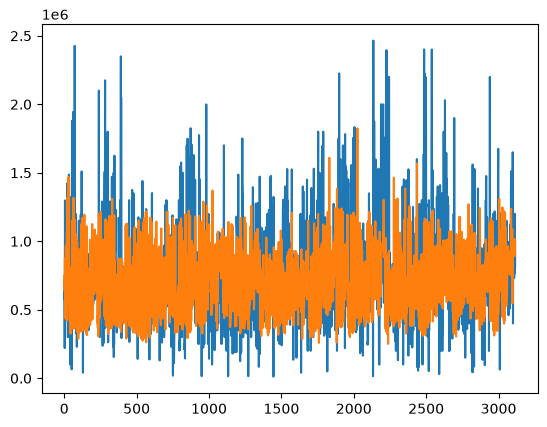

In [52]:
import matplotlib.pyplot as plt

plt.plot(y_val_sc)
plt.plot(pred_val)